# Assignment 1

### Students: <br>
Anton Maksymchuk Netterström <br>
Mauritz Almgren

Following dependencies is required to run the code

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


Data fetching and preprocessing

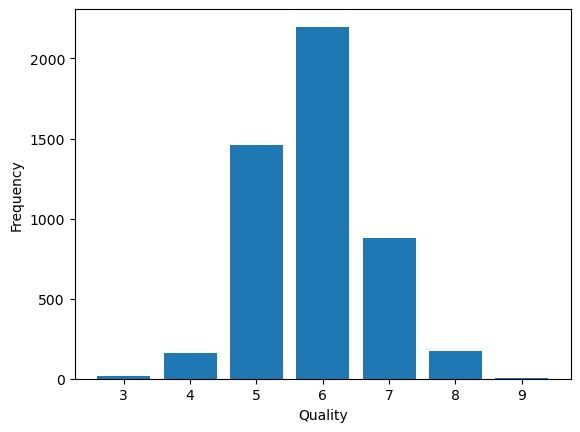

Unique quality quality
6    2198
5    1457
7     880
8     175
4     163
3      20
9       5
Name: count, dtype: int64


In [2]:
df = pd.read_csv('winequality-white.csv', sep=';')

# Get value for each 'quality' 
count_unique = df['quality'].value_counts()

# Bar chart for quality BEFORE SMOTE
plt.bar(count_unique.index, count_unique.values)
plt.xlabel('Quality')
plt.ylabel('Frequency')
plt.show()


print('Unique quality', count_unique)


In [3]:
# Data splitting - Baseline. Let X be all columns exepct quality and let Y be the column quality
X = df.drop(columns=['quality'])
y = df['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


Logistic regression classifier (with solver lbfgs as this is a multiclass classification problem)

In [4]:
# Logistic Regression classifier (lbfgs)
rkf = RepeatedStratifiedKFold(n_splits=3, n_repeats=10, random_state=42)
rkf.get_n_splits()
pipe = Pipeline([('scaler', StandardScaler()), ('classifier', LogisticRegression(solver='lbfgs', max_iter=2000))])
scores = cross_val_score(pipe, X_train, y_train, cv=rkf, scoring='f1_macro')


print(f"Cross-validation accuracy scores: {scores}")
print(f"Mean CV accuracy: {np.mean(scores):.4f}")
print(f"Standard deviation of CV accuracy: {np.std(scores):.4f}")

Cross-validation accuracy scores: [0.20618191 0.21978109 0.24354059 0.22841862 0.23379555 0.28212981
 0.24120611 0.27247924 0.20538663 0.27265727 0.22130133 0.22195812
 0.23269417 0.2191153  0.23051513 0.22157889 0.21247191 0.23443708
 0.22429616 0.2384661  0.21472071 0.22369465 0.22941083 0.21681519
 0.22967432 0.22249126 0.22299516 0.28102603 0.21707468 0.22863846]
Mean CV accuracy: 0.2316
Standard deviation of CV accuracy: 0.0200


Random forest classifier

In [5]:
# Random forest classifier
pipe2 = Pipeline([('scalar', StandardScaler()), ('classifier', RandomForestClassifier(random_state=42))])
scores = cross_val_score(pipe2, X_train, y_train, cv=rkf, scoring='f1_macro')


print(f"Cross-validation F1 score: {scores}")
print(f"Mean CV F1 score: {np.mean(scores):.4f}")
print(f"Standard deviation of CV F1 score: {np.std(scores):.4f}")


Cross-validation F1 score: [0.34611769 0.33200189 0.38292682 0.36824223 0.35895863 0.34849427
 0.36335716 0.3406071  0.37466667 0.35588113 0.36669018 0.35854347
 0.38444652 0.3485748  0.34496237 0.38116627 0.36396055 0.34430282
 0.36541568 0.35952266 0.35108751 0.34276368 0.32948291 0.38114401
 0.36752094 0.3755807  0.36566085 0.37323127 0.37777469 0.39373337]
Mean CV F1 score: 0.3616
Standard deviation of CV F1 score: 0.0160


As Random forest classifier gave the 'best' F1 Macro, Random forest will be used for final test

In [59]:
pipe2.fit(X_train, y_train)

# Predict on held-out test set
y_pred = pipe2.predict(X_test)

# Evaluate
f1_macro = f1_score(y_test, y_pred, average='macro')

print(f"Final test F1 Macro: {f1_macro:.4f}")

report_without_SMOTE = classification_report(y_test, y_pred, zero_division=0, output_dict=True)
print(report_without_SMOTE)

Final test F1 Macro: 0.4277
{'3': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 4.0}, '4': {'precision': 0.7, 'recall': 0.21212121212121213, 'f1-score': 0.32558139534883723, 'support': 33.0}, '5': {'precision': 0.7084870848708487, 'recall': 0.6597938144329897, 'f1-score': 0.6832740213523132, 'support': 291.0}, '6': {'precision': 0.6410714285714286, 'recall': 0.8159090909090909, 'f1-score': 0.718, 'support': 440.0}, '7': {'precision': 0.7142857142857143, 'recall': 0.48295454545454547, 'f1-score': 0.576271186440678, 'support': 176.0}, '8': {'precision': 0.95, 'recall': 0.5428571428571428, 'f1-score': 0.6909090909090909, 'support': 35.0}, '9': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 1.0}, 'accuracy': 0.6755102040816326, 'macro avg': {'precision': 0.5305491753897131, 'recall': 0.3876622579678544, 'f1-score': 0.4277193848644171, 'support': 980.0}, 'weighted avg': {'precision': 0.6839851591664604, 'recall': 0.6755102040816326, 'f1-score': 0.6643902788320

Smote implementation

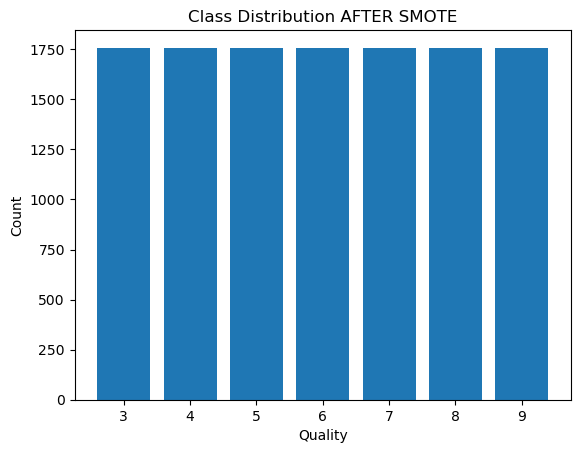

In [7]:
smote = SMOTE(sampling_strategy='not majority', random_state=42, k_neighbors=1)

X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

plt.bar(y_train_sm.value_counts().index, y_train_sm.value_counts().values)
plt.xlabel('Quality')
plt.ylabel("Count")
plt.title("Class Distribution AFTER SMOTE")
plt.show()


Logistic regression and random forest classifier with SMOTE implementation

In [8]:
pipe_lr = ImbPipeline([('scalar', StandardScaler()), ('smote', smote), ('classifier', LogisticRegression(solver='lbfgs', max_iter=2000))])
scores = cross_val_score(pipe_lr, X_train, y_train, cv=rkf, scoring='f1_macro')

print(f"Cross-validation F1 score: {scores}")
print(f"Mean CV F1 score: {np.mean(scores):.4f}")
print(f"Standard deviation of CV F1 score: {np.std(scores):.4f}")

Cross-validation F1 score: [0.21821168 0.23087677 0.22353386 0.21848908 0.22254869 0.22031948
 0.19748447 0.2158576  0.21011748 0.21413288 0.21502402 0.20920718
 0.22258616 0.21718049 0.22320265 0.2117479  0.22035548 0.19463502
 0.22145837 0.21148711 0.23083073 0.20398855 0.21570747 0.22736431
 0.22681481 0.22299953 0.21969839 0.22343317 0.18400488 0.20958405]
Mean CV F1 score: 0.2161
Standard deviation of CV F1 score: 0.0103


In [9]:
pipe_rf = ImbPipeline([('scalar', StandardScaler()), ('smote', smote), ('classifier', RandomForestClassifier(random_state=42))])
scores = cross_val_score(pipe_rf, X_train, y_train, cv=rkf, scoring='f1_macro')


print(f"Cross-validation accuracy scores: {scores}")
print(f"Mean CV accuracy: {np.mean(scores):.4f}")
print(f"Standard deviation of CV accuracy: {np.std(scores):.4f}")

Cross-validation accuracy scores: [0.35044242 0.34840565 0.38374314 0.3681157  0.36904862 0.40739553
 0.35930875 0.35682983 0.38105173 0.37735499 0.40067126 0.35598358
 0.378264   0.36060683 0.35285346 0.38784138 0.36184847 0.34936222
 0.39196669 0.36759847 0.35277876 0.35835821 0.34455658 0.37344102
 0.38725608 0.37427887 0.38184226 0.41323136 0.36217841 0.3796297 ]
Mean CV accuracy: 0.3712
Standard deviation of CV accuracy: 0.0176


Final balanced training and testing for random forest classifier

In [12]:
pipe_rf.fit(X_train, y_train)

y_pred = pipe_rf.predict(X_test)

f1_macro = f1_score(y_test, y_pred, average='macro')

print(f"Final test Macro F1: {f1_macro:.4f}")

report_with_SMOTE = classification_report(y_test, y_pred, zero_division=0, output_dict=True)
print(report_with_SMOTE)

Final test Macro F1: 0.4344
{'3': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 4.0}, '4': {'precision': 0.4827586206896552, 'recall': 0.42424242424242425, 'f1-score': 0.45161290322580644, 'support': 33.0}, '5': {'precision': 0.6829268292682927, 'recall': 0.6735395189003437, 'f1-score': 0.6782006920415224, 'support': 291.0}, '6': {'precision': 0.6703296703296703, 'recall': 0.6931818181818182, 'f1-score': 0.6815642458100558, 'support': 440.0}, '7': {'precision': 0.601123595505618, 'recall': 0.6079545454545454, 'f1-score': 0.6045197740112994, 'support': 176.0}, '8': {'precision': 0.6896551724137931, 'recall': 0.5714285714285714, 'f1-score': 0.625, 'support': 35.0}, '9': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 1.0}, 'accuracy': 0.6551020408163265, 'macro avg': {'precision': 0.4466848411724328, 'recall': 0.42433526831538615, 'f1-score': 0.43441394501266917, 'support': 980.0}, 'weighted avg': {'precision': 0.6525953883554677, 'recall': 0.655102040816326

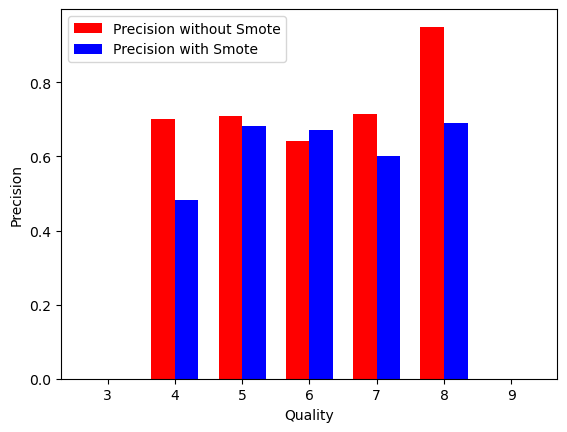

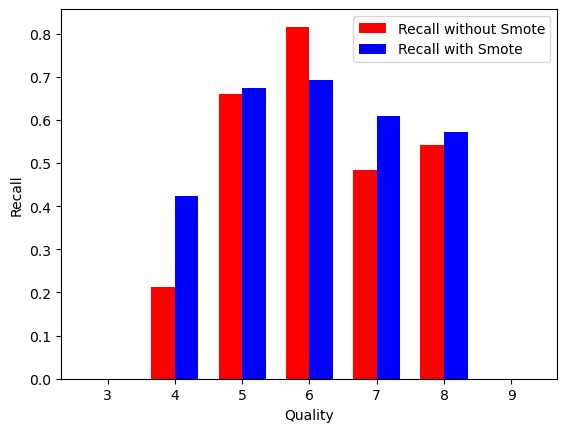

In [75]:
width = 0.35

keys_reg = list(report_without_SMOTE.keys())[:7]
items_reg = []

for key in keys_reg:
    for item in list(report_without_SMOTE[key].items()):
        if item[0] == "precision":
            items_reg.append(item[1])


keys_smote = list(report_with_SMOTE.keys())[:7]
items_smote = []
for key in keys_smote: 
    for item in list(report_with_SMOTE[key].items()):
        if item[0] == "precision":
            items_smote.append(item[1])


plt.bar(keys_reg, items_reg, -width, align="edge", color="r", label="Precision without Smote")
plt.bar(keys_smote, items_smote, +width, align="edge", color="b", label="Precision with Smote")

plt.xlabel("Quality")
plt.ylabel("Precision")
plt.legend()
plt.show()

items_reg = []

for key in keys_reg:
    for item in list(report_without_SMOTE[key].items()):
        if item[0] == "recall":
            items_reg.append(item[1])

items_smote = []
for key in keys_smote: 
    for item in list(report_with_SMOTE[key].items()):
        if item[0] == "recall":
            items_smote.append(item[1])

plt.bar(keys_reg, items_reg, -width, align="edge", color="r", label="Recall without Smote")
plt.bar(keys_smote, items_smote, +width, align="edge", color="b", label="Recall with Smote")

plt.xlabel("Quality")
plt.ylabel("Recall")
plt.legend()
plt.show()